# House Stage 2: H2: regional factor

The `02_monte_carlo.ipynb` simulation (H0: national + state + district), plus a political-region shock.

$e_{d} = N + S_s + D_d + R_{g(s)}$: one regional draw per political region per simulation, shared by every district of its states, with one common scale for the 10 regions.

The race handling, the Stage 1 configurations, the calibration years and the seeds are exactly those of `02_monte_carlo.ipynb`. H0 runs alongside as the reference. Its numbers are identical to 02's.

The question is whether the factor improves the **joint** distribution of outcomes (seats that swing together), not just district Brier scores.

**Estimation** (`simulation.estimate_factor_sds`, `src/house/simulation/factors.py`, whose docstring has the details). Every component is fit on Stage 1's rolling out-of-sample residuals from the training elections only.

- **National:** H0's estimator, unchanged. The fixed 3-point prior SD counts as 2 pseudo-elections.
- **Demographic:** each year's within-state-year slope of the residual on $Z$ is one observation, net of its sampling variance. The coefficient variance is $\max(0, \sum_y(\hat\gamma_y^2 - se_y^2)) / (n_0 + K)$.
- **Regional:** each year's same-region minus different-region state-pair covariance, corrected for the bias that centering on the year mean causes (validated on synthetic data with unequal states and regions). The variance is $\max(0, \sum_y m_y) / (n_0 + K)$.
- **Shrinkage:** both factors use a zero prior with $n_0$ = 3 pseudo-elections. It was fixed in advance and is not tuned on this backtest.
- **Budget:** the factors take their variance out of H0's state and district levels, $\sigma_S^2 = \sigma_{S0}^2 - \sigma_R^2 - \sigma_\gamma^2 B$ and $\sigma_D^2 = \sigma_{D0}^2 - \sigma_\gamma^2 W$. An average district's error variance is therefore exactly H0's, and only the correlations change. A cap shrinks the factors themselves and is reported in `cap`.
- **Approximation:** the national estimator's yearly mean already contains the district-weighted average of that year's regional shocks. $\sigma_N$ is kept as in H0, so the simulated House-wide mean error can be slightly wider than in H0. `sim sd of mean error` reports it.

With only three backtest elections, every comparison here is exploratory.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))  # for experiments.house
import house.regression as hr
from house import simulation, stage1

In [2]:
HIERARCHY = "H2"
CONFIG = stage1.HOUSE_ENSEMBLE_AB_85_15  # the production Stage 1 configuration (2026 forecast)
FALLBACK_CONFIG = stage1.HOUSE_MODEL_A  # predicts a D-vs-R race CONFIG lacks inputs for
CALIBRATION_CONFIGS = {c.name: c for c in [stage1.HOUSE_MODEL_A, stage1.HOUSE_ENSEMBLE_AB_85_15]}
HOUSE_SEATS = 435

SEED = 42
N_SIMS = 40_000
NU = 5                          # Student-t degrees of freedom, every component
NATIONAL_PRIOR_SD = 3.0         # points; H0's, fixed
NATIONAL_PRIOR_ELECTIONS = 2
REGIONAL_PRIOR_ELECTIONS = 3    # zero prior on the regional variance, in pseudo-elections; fixed, not tuned
DEMOGRAPHIC_PRIOR_ELECTIONS = 3  # zero prior on the demographic coefficient variance; fixed, not tuned
COLLEGE_REFERENCE_SD = 10.0     # points of college share per unit of Z (units only; margins don't depend on it)
CALIBRATION_YEARS = [2020, 2022, 2024]  # 2018 only initializes the 2020 fit

In [3]:
with warnings.catch_warnings(action="ignore"):  # loading warns about known optional-column gaps
    predictors = hr.load_predictors()  # data/processed/house/modeling.csv, 2006-2026
    targets = hr.load_targets()        # data/processed/house/targets.csv, 2006-2024
targets_raw = simulation.load_targets_raw()
candidates = simulation.load_candidates_2026()
races = simulation.historical_races(targets, targets_raw)  # lineups, treatments, observed winners and margins

stage1_runs = {name: simulation.stage1_inputs(config, predictors=predictors, targets=targets)
               for name, config in CALIBRATION_CONFIGS.items()}

## 1. Factor inputs

The 10 political regions come from `data/reference/regional_stage2.csv`. The demographic loading is each district's college share (adults 25+ with a bachelor's degree, ACS) minus the year's 435-district mean, divided by 10 points.

In [4]:
REGIONS = simulation.load_regions(simulation.REGIONS_PATH)  # raises unless all 50 states appear exactly once
LOADINGS = simulation.demographic_loadings(predictors, column="college", reference_sd=COLLEGE_REFERENCE_SD)

display(REGIONS.groupby(REGIONS).apply(lambda s: ", ".join(s.index)).rename("states").to_frame())
# Z is centered each year (sum over the 435 districts = 0), so a demographic draw never moves the national average
LOADINGS.groupby("year")["demographic_loading"].agg(districts="size", sum="sum", sd="std", min="min", max="max").round(3)

,states
region,
Mid-Atlantic,"CT, DE, MD, NJ, NY, RI"
Mountain West,"AK, ID, MT, UT, WY"
Northeast,"MA, ME, NH, VT"
Plains,"KS, ND, NE, OK, SD"
Rust Belt,"IA, IL, IN, MI, MN, OH, PA, WI"
South,"AL, AR, KY, LA, MO, MS, WV"
Southeast,"GA, NC, SC, VA"
Southwest,"AZ, CO, NM, NV"
Texas-Florida,"FL, TN, TX"


,districts,sum,sd,min,max
year,,,,,
2006,435,0.0,0.969,-2.048,3.783
2008,435,0.0,0.970,-2.054,3.836
2010,435,0.0,0.970,-2.081,3.616
2012,435,-0.0,1.008,-2.103,4.148
2014,435,-0.0,1.032,-2.258,4.206
2016,435,-0.0,1.055,-2.303,4.128
2018,435,0.0,1.092,-2.296,4.181
2020,435,0.0,1.083,-2.297,4.076
2022,435,0.0,1.107,-2.518,4.691


## 2. Error model by training window

The components each test year (and 2026) is simulated with, for the production configuration, each fit only on the elections before it. `h0 sd` is H0's value and `sd` the allocated one. `district variance` is each component's share of an average district's error variance; apart from the national row, these add up exactly to H0's state + district variance (`check_variance_budget`).

In [5]:
oos = stage1_runs[CONFIG.name].oos
error_models = {}
for year in [*CALIBRATION_YEARS, 2026]:
    train = oos[oos["year"] < year]
    h0_sds, _ = simulation.estimate_error_sds(train, national_prior_sd=NATIONAL_PRIOR_SD,
                                              national_prior_elections=NATIONAL_PRIOR_ELECTIONS)
    sds, details = simulation.estimate_factor_sds(
        train,
        regions=REGIONS,
        loadings=None,
        national_prior_sd=NATIONAL_PRIOR_SD,
        national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
        regional_prior_elections=REGIONAL_PRIOR_ELECTIONS,
        demographic_prior_elections=DEMOGRAPHIC_PRIOR_ELECTIONS,
    )
    print(year, simulation.check_variance_budget(sds, details, h0_sds))
    error_models[year] = details.assign(**{f"t scale (nu = {NU})": {c: simulation.t_scale(sd, NU) for c, sd in sds.items()}})
pd.concat(error_models, names=["fit for"]).round(3)

2020 variance budget checks passed: components national, state, district, region, sub-national variance 51.461 = H0's 51.461; no cap binds
2022 variance budget checks passed: components national, state, district, region, sub-national variance 45.265 = H0's 45.265; no cap binds
2024 variance budget checks passed: components national, state, district, region, sub-national variance 43.378 = H0's 43.378; no cap binds
2026 variance budget checks passed: components national, state, district, region, sub-national variance 41.712 = H0's 41.712; no cap binds


unit  observations  unregularized sd  h0 sd  \
fit for component                                                         
2020    national        election             1             1.227  2.550   
        state         state-year            50             4.096  4.096   
        district   district-year           393             5.889  5.889   
        region       region-year            10             1.713    NaN   
2022    national        election             2             2.320  2.682   
        state         state-year            99             3.481  3.481   
        district   district-year           801             5.757  5.757   
        region       region-year            20             1.842    NaN   
2024    national        election             3             2.081  2.490   
        state         state-year           147             3.749  3.749   
        district   district-year          1200             5.415  5.415   
        region       region-year            30             1.914    NaN   
2026    national        election             4             1.945  2.350   
        state         state-year           197             3.666  3.666   
        district   district-year          1598             5.317  5.317   
        region       region-year            40             1.904    NaN   

                   regularized sd     sd  district variance  \
fit for component                                             
2020    national            2.550  2.550              6.502   
        state               4.096  4.006             16.046   
        district            5.889  5.889             34.682   
        region              0.856  0.856              0.733   
2022    national            2.682  2.682              7.192   
        state               3.481  3.280             10.760   
        district            5.757  5.757             33.148   
        region              1.165  1.165              1.357   
2024    national            2.490  2.490              6.199   
        state               3.749  3.497             12.226   
        district            5.415  5.415             29.320   
        region              1.354  1.354              1.832   
2026    national            2.350  2.350              5.521   
        state               3.666  3.371             11.365   
        district            5.317  5.317             28.274   
        region              1.440  1.440              2.072   

                                                      regularization cap  \
fit for component                                                          
2020    national                     prior sd 3 x 2 pseudo-elections       
        state      H0 state budget, less the factors' between-sta...       
        district   H0 district budget, less the demographic withi...       
        region                       prior sd 0 x 3 pseudo-elections       
2022    national                     prior sd 3 x 2 pseudo-elections       
        state      H0 state budget, less the factors' between-sta...       
        district   H0 district budget, less the demographic withi...       
        region                       prior sd 0 x 3 pseudo-elections       
2024    national                     prior sd 3 x 2 pseudo-elections       
        state      H0 state budget, less the factors' between-sta...       
        district   H0 district budget, less the demographic withi...       
        region                       prior sd 0 x 3 pseudo-elections       
2026    national                     prior sd 3 x 2 pseudo-elections       
        state      H0 state budget, less the factors' between-sta...       
        district   H0 district budget, less the demographic withi...       
        region                       prior sd 0 x 3 pseudo-elections       

                   t scale (nu = 5)  
fit for component                    
2020    national              1.975  
        state                 3.103  
        district     

In [6]:
# The per-election observations behind the 2026 fit (2018-2024): demographic slope and its SE, the regional moment
# before (region_c) and after its centering-bias correction (region_a, region_b)
simulation.factor_moments(oos, regions=REGIONS, loadings=None).round(3)

,districts,region_c,region_a,region_b,region_moment,region_years
year,,,,,,
2018,393,2.807,0.076,-0.007,2.959,10
2020,408,3.603,0.073,-0.008,3.805,10
2022,399,4.059,0.058,-0.007,4.243,10
2024,398,3.371,0.063,-0.009,3.500,10


## 3. Calibration backtest

Both Stage 1 configurations, under H0 and H2, with the same draws seed per test year. Only the error model differs.

In [7]:
calibration = {"H0": {}, HIERARCHY: {}}
for name, run in stage1_runs.items():
    calibration["H0"][name] = simulation.backtest(
        run.oos,
        test_years=CALIBRATION_YEARS,
        races=races,
        predictions=run.predictions,
        fallback_predictions=stage1_runs[FALLBACK_CONFIG.name].predictions,
        nu=NU,
        n_sims=N_SIMS,
        seed=SEED,
        house_size=HOUSE_SEATS,
        national_prior_sd=NATIONAL_PRIOR_SD,
        national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
    )
    calibration[HIERARCHY][name] = simulation.backtest(
        run.oos,
        test_years=CALIBRATION_YEARS,
        races=races,
        predictions=run.predictions,
        fallback_predictions=stage1_runs[FALLBACK_CONFIG.name].predictions,
        nu=NU,
        n_sims=N_SIMS,
        seed=SEED,
        house_size=HOUSE_SEATS,
        national_prior_sd=NATIONAL_PRIOR_SD,
        national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
        regions=REGIONS,
        loadings=None,
        regional_prior_elections=REGIONAL_PRIOR_ELECTIONS,
        demographic_prior_elections=DEMOGRAPHIC_PRIOR_ELECTIONS,
    )

In [8]:
# Checks: no leakage (each year's SDs are those of earlier residuals), every race once, each race's own region and
# loading, the engine's own draws, the variance budget, reproducibility
for name, run in stage1_runs.items():
    print(simulation.check_backtest(calibration["H0"][name], run, races, house_size=HOUSE_SEATS, n_sims=N_SIMS,
                                    national_prior_sd=NATIONAL_PRIOR_SD,
                                    national_prior_elections=NATIONAL_PRIOR_ELECTIONS))
    print(simulation.check_backtest(calibration[HIERARCHY][name], run, races, house_size=HOUSE_SEATS, n_sims=N_SIMS,
                                    national_prior_sd=NATIONAL_PRIOR_SD,
                                    national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
                                    regions=REGIONS, loadings=None,
                                    regional_prior_elections=REGIONAL_PRIOR_ELECTIONS,
                                    demographic_prior_elections=DEMOGRAPHIC_PRIOR_ELECTIONS))
    for year, result in calibration[HIERARCHY][name].years.items():
        h0_result = calibration["H0"][name].years[year]
        print(" ", year, simulation.check_variance_budget(result.error_sd, result.error_details, h0_result.error_sd))
year = CALIBRATION_YEARS[-1]
print(simulation.check_engine_draws(calibration[HIERARCHY][CONFIG.name].years[year], nu=NU, n_sims=N_SIMS, seed=SEED))

rerun = simulation.backtest(  # one seed, one result
    stage1_runs[CONFIG.name].oos,
    test_years=[year],
    races=races,
    predictions=stage1_runs[CONFIG.name].predictions,
    fallback_predictions=stage1_runs[FALLBACK_CONFIG.name].predictions,
    nu=NU,
    n_sims=N_SIMS,
    seed=SEED,
    house_size=HOUSE_SEATS,
    national_prior_sd=NATIONAL_PRIOR_SD,
    national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
        regions=REGIONS,
        loadings=None,
        regional_prior_elections=REGIONAL_PRIOR_ELECTIONS,
        demographic_prior_elections=DEMOGRAPHIC_PRIOR_ELECTIONS,
)
print(simulation.check_same_draws(rerun.years[year], calibration[HIERARCHY][CONFIG.name].years[year]))

backtest checks passed: house_model_a (national, state, district), 2020, 2022, 2024
backtest checks passed: house_model_a (national, state, district, region), 2020, 2022, 2024
  2020 variance budget checks passed: components national, state, district, region, sub-national variance 60.790 = H0's 60.790; no cap binds
  2022 variance budget checks passed: components national, state, district, region, sub-national variance 53.705 = H0's 53.705; no cap binds
  2024 variance budget checks passed: components national, state, district, region, sub-national variance 50.132 = H0's 50.132; no cap binds
backtest checks passed: house_ensemble_ab_85_15 (national, state, district), 2020, 2022, 2024
backtest checks passed: house_ensemble_ab_85_15 (national, state, district, region), 2020, 2022, 2024
  2020 variance budget checks passed: components national, state, district, region, sub-national variance 51.461 = H0's 51.461; no cap binds
  2022 variance budget checks passed: components national, state

engine draw checks passed: 2024, 398 simulated races


reproducibility check passed: identical draws


### Calibration by election

The columns are those of `02_monte_carlo.ipynb`: Brier over every resolved race, the contested D-vs-R races, and the ex-ante competitive ones; 80% and 95% margin coverage; and the seat median, intervals, actual count and its percentile, over the matched panel (all 435 races in 2020–2024).

In [9]:
simulation.styled(simulation.stack(calibration, "table", outer="hierarchy"))

In [10]:
# Mean interval widths, every component's SD and t scale, and the simulated SD of the House-wide mean error
# (the national overlap: compare with national sd)
diagnostics = simulation.stack(calibration, "diagnostics", outer="hierarchy")
simulation.styled(diagnostics.filter(regex="sd|scale|width|mean_signed_error"))

### Joint distribution: seats within groups

`simulation.group_seats` scores the seats of each group of races against the draws: the median, the 80% and 95% intervals, and whether they contain the actual count. If the model leaves out a correlation, the group's simulated seats are too narrow and its actual counts fall outside too often. The same groupings score every hierarchy:

- **political region:** 10 groups × 3 elections. This grouping favors H2 by construction.
- **college tercile:** each year's districts in thirds by $Z$. This one favors H1.
- **competitive:** ex-ante competitive D-vs-R races (`True`) and the other simulated races (`False`). Correlated competitive-seat swings show up here.

Each election contributes one count per group, so these are a few dozen observations at most. Read them as direction, not proof.

In [11]:
region_groups = races[hr.KEY].assign(region=races["state"].map(REGIONS))
college_groups = simulation.college_terciles(LOADINGS)
group_tables = {
    "region": simulation.stack(calibration, lambda cal: simulation.group_seats(cal, "region", region_groups),
                               outer="hierarchy"),
    "college tercile": simulation.stack(calibration, lambda cal: simulation.group_seats(cal, "college_tercile",
                                                                                        college_groups),
                                        outer="hierarchy"),
    "competitive": simulation.stack(calibration, lambda cal: simulation.group_seats(cal, "competitive_ex_ante"),
                                    outer="hierarchy"),
}
summary = pd.concat({grouping: table.groupby(["hierarchy", "config"])[
    ["inside 80%", "inside 95%", "80% seat width", "95% seat width"]].mean()
    for grouping, table in group_tables.items()}, names=["grouping"])
summary.round(3)

inside 80%  inside 95%  \
grouping        hierarchy config                                            
region          H0        house_ensemble_ab_85_15       0.833       1.000   
                          house_model_a                 0.900       1.000   
                H2        house_ensemble_ab_85_15       0.867       1.000   
                          house_model_a                 0.933       1.000   
college tercile H0        house_ensemble_ab_85_15       0.889       1.000   
                          house_model_a                 0.889       1.000   
                H2        house_ensemble_ab_85_15       0.889       1.000   
                          house_model_a                 0.889       1.000   
competitive     H0        house_ensemble_ab_85_15       0.667       0.833   
                          house_model_a                 0.833       0.833   
                H2        house_ensemble_ab_85_15       0.667       0.833   
                          house_model_a                 0.833       0.833   

                                                   80% seat width  \
grouping        hierarchy config                                    
region          H0        house_ensemble_ab_85_15           3.367   
                          house_model_a                     3.633   
                H2        house_ensemble_ab_85_15           3.533   
                          house_model_a                     3.700   
college tercile H0        house_ensemble_ab_85_15           8.222   
                          house_model_a                     8.667   
                H2        house_ensemble_ab_85_15           8.222   
                          house_model_a                     8.889   
competitive     H0        house_ensemble_ab_85_15          11.500   
                          house_model_a                    12.167   
                H2        house_ensemble_ab_85_15          11.667   
                          house_model_a                    12.333   

                                                   95% seat width  
grouping        hierarchy config                                   
region          H0        house_ensemble_ab_85_15           5.333  
                          house_model_a                     5.767  
                H2        house_ensemble_ab_85_15           5.333  
                          house_model_a                     5.833  
college tercile H0        house_ensemble_ab_85_15          13.333  
                          house_model_a                    14.333  
                H2        house_ensemble_ab_85_15          13.667  
                          house_model_a                    14.444  
competitive     H0        house_ensemble_ab_85_15          19.333  
                          house_model_a                    20.500  
                H2        house_ensemble_ab_85_15          19.500  
                          house_model_a                    20.667

In [12]:
simulation.styled(group_tables["competitive"])

### Seat distributions

The stored draws for each hierarchy × configuration (rows) and test year (columns). Columns share an x range.

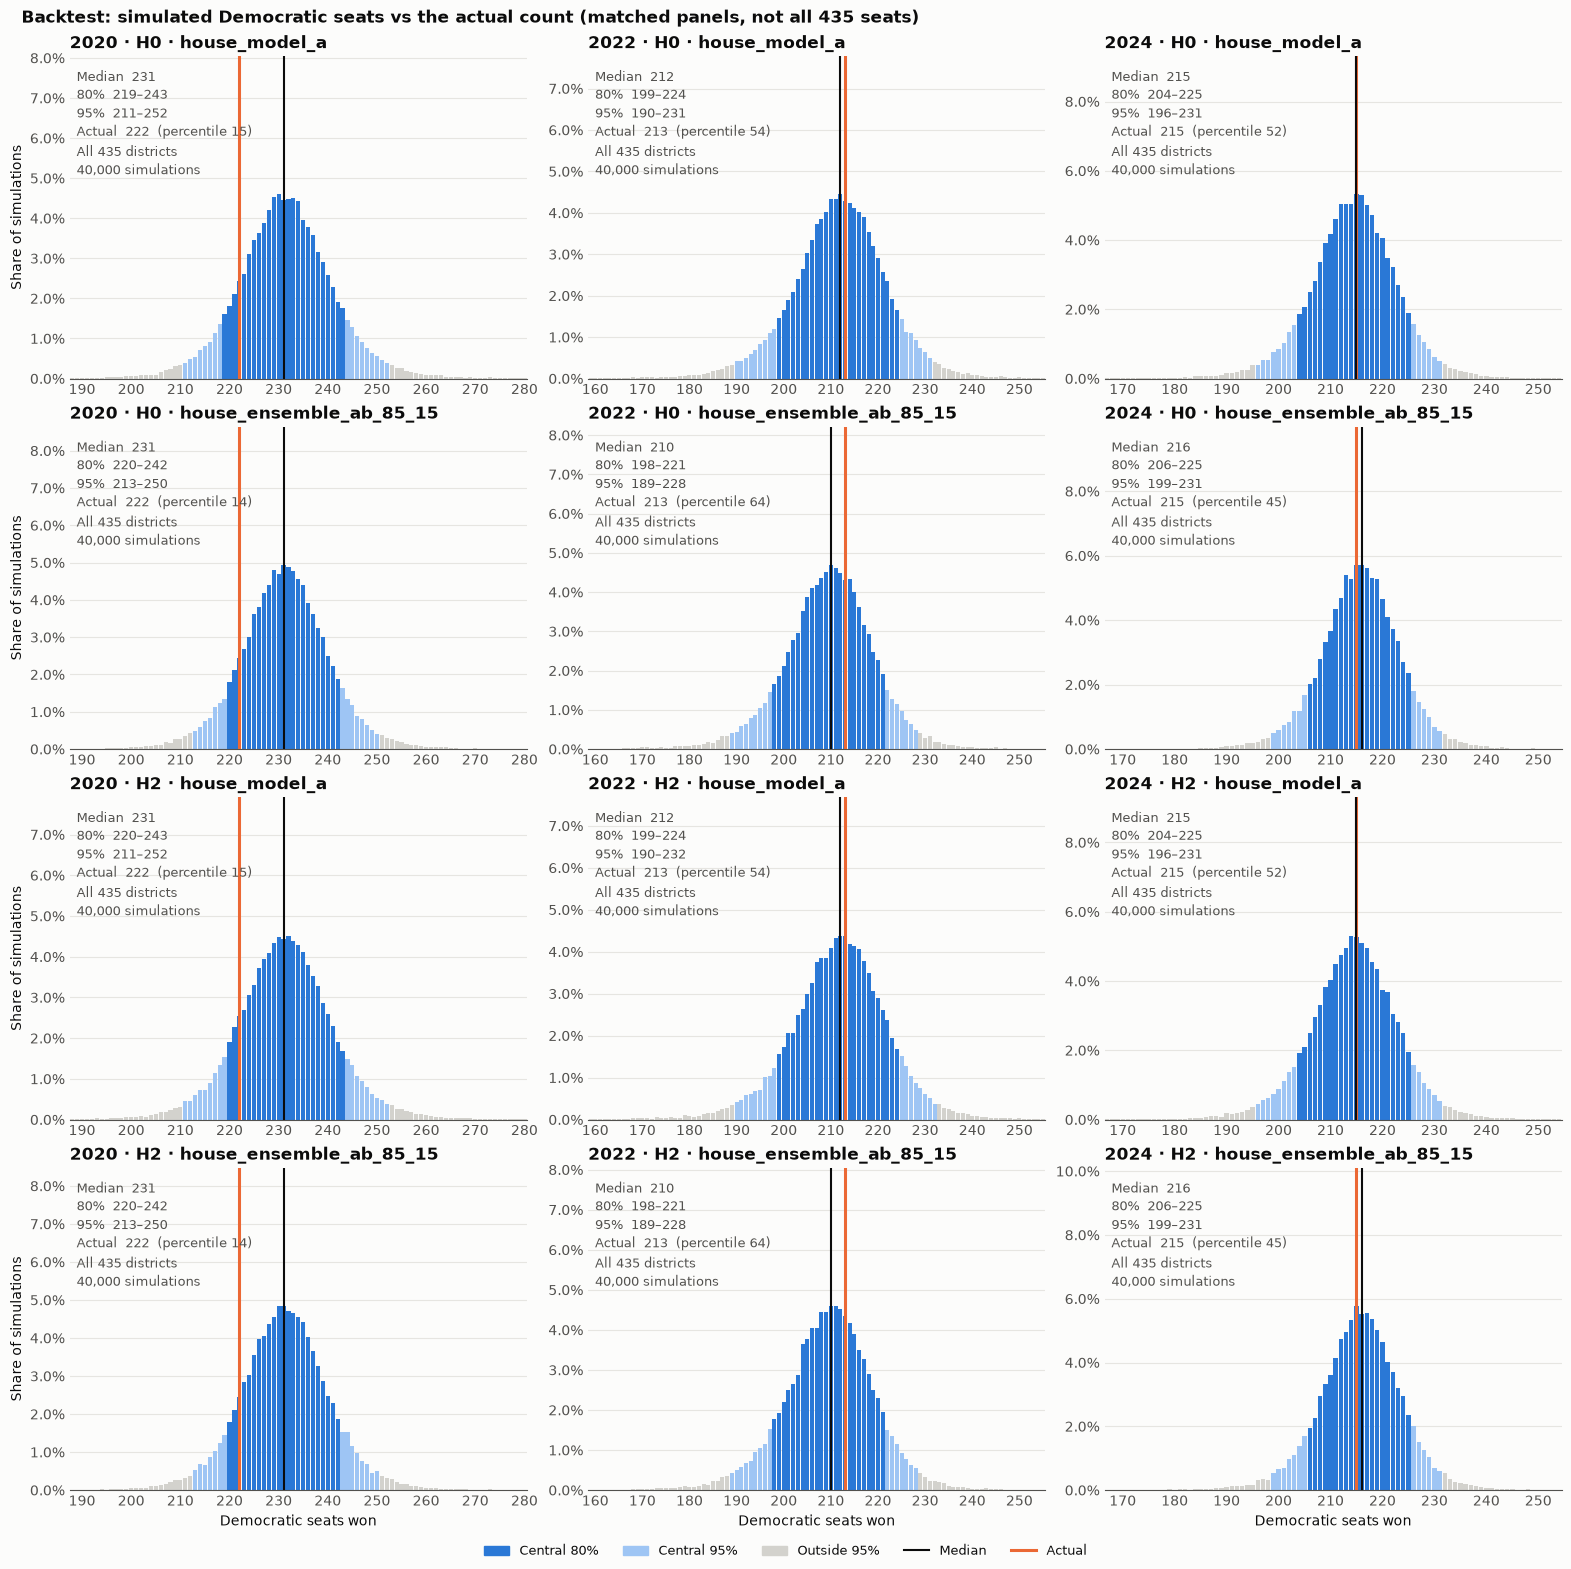

In [13]:
by_row = {f"{hierarchy} · {name}": cal for hierarchy, cals in calibration.items() for name, cal in cals.items()}
fig, axes = simulation.plot_backtest_seat_distributions(by_row)

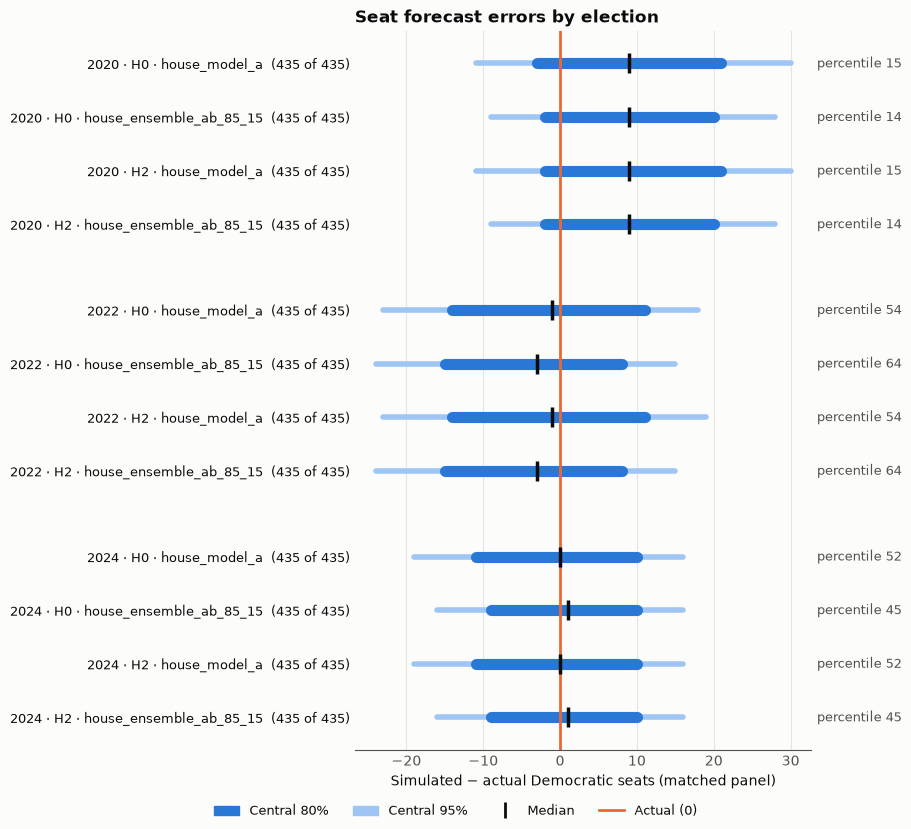

In [14]:
fig, ax = simulation.plot_seat_errors(by_row)

## 4. 2026 forecast under H2

The production forecast of `02_monte_carlo.ipynb`, section 5, with this error model fit on the 2018–2024 residuals (section 2's `fit for 2026` rows). The lineups, the rule-decided races, the CA-6 handling and the seed are the same.

In [15]:
FORECAST_YEAR = 2026
RESOLVERS = []  # hooks, default behavior

forecast = simulation.stage1_forecast(CONFIG, predictors=predictors, targets=targets)
fallback_forecast = simulation.stage1_forecast(FALLBACK_CONFIG, predictors=predictors, targets=targets)
point_2026 = simulation.attach_predictions(simulation.races_2026(candidates), forecast.predictions,
                                           primary_source=CONFIG.name, fallback=fallback_forecast.predictions)
point_2026 = simulation.attach_factors(point_2026, regions=REGIONS, loadings=None)

ERROR_SD_2026, error_details_2026 = simulation.estimate_factor_sds(
    oos,  # every Stage 1 out-of-sample year, 2018-2024
    regions=REGIONS,
    loadings=None,
    national_prior_sd=NATIONAL_PRIOR_SD,
    national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
    regional_prior_elections=REGIONAL_PRIOR_ELECTIONS,
    demographic_prior_elections=DEMOGRAPHIC_PRIOR_ELECTIONS,
)
ERROR_SCALE_2026 = {c: simulation.t_scale(sd, NU) for c, sd in ERROR_SD_2026.items()}
H0_SD_2026, _ = simulation.estimate_error_sds(oos, national_prior_sd=NATIONAL_PRIOR_SD,
                                              national_prior_elections=NATIONAL_PRIOR_ELECTIONS)
print(simulation.check_variance_budget(ERROR_SD_2026, error_details_2026, H0_SD_2026))

draws_2026 = simulation.simulate_races(point_2026, ERROR_SCALE_2026, NU, N_SIMS,
                                       np.random.default_rng([SEED, FORECAST_YEAR]), resolvers=RESOLVERS)
forecast_2026 = simulation.forecast_table(draws_2026, candidates, resolvers=RESOLVERS)
forecast_2026.groupby(["treatment", "race_type", "prediction_source"]).size().rename("races")

variance budget checks passed: components national, state, district, region, sub-national variance 41.712 = H0's 41.712; no cap binds


treatment    race_type        prediction_source      
fixed        dem_uncontested  fixed                        5
same_party   dem_vs_dem       same_party                   8
             gop_vs_gop       same_party                   1
simulated    dr               house_ensemble_ab_85_15    408
             dr_jungle        house_ensemble_ab_85_15      6
             dr_rcv           house_ensemble_ab_85_15      3
third_party  dem_vs_3p        third_party                  4
Name: races, dtype: int64

In [16]:
# The raw engine on the simulated races: every component shared at its level, with the right SDs
simulated_2026 = point_2026[point_2026["treatment"] == "simulated"]
sims, draws = simulation.simulate_margins(simulated_2026, ERROR_SCALE_2026, NU, N_SIMS, np.random.default_rng(SEED))
print(simulation.check_engine(sims, draws, simulated_2026, ERROR_SD_2026, ERROR_SCALE_2026, NU))

engine checks passed: 40,000 simulations x 417 districts in 50 states, 10 regions; components national, state, district, region


In [17]:
# Seats by ballot party: the official count and the optional caucus scenario; H0's official count for reference
KILEY_CAUCUSES_R = {(2026, "CA", 6): simulation.GOP}
SEAT_SCENARIOS = {"official": None, "Kiley caucuses R": KILEY_CAUCUSES_R}
h0_draws_2026 = simulation.simulate_races(point_2026, {level: simulation.t_scale(sd, NU) for level, sd in H0_SD_2026.items()},
                                          NU, N_SIMS, np.random.default_rng([SEED, FORECAST_YEAR]), resolvers=RESOLVERS)
simulation.styled(pd.concat({HIERARCHY: simulation.seat_table(draws_2026, SEAT_SCENARIOS),
                             "H0": simulation.seat_table(h0_draws_2026, {"official": None})}, names=["hierarchy"]))

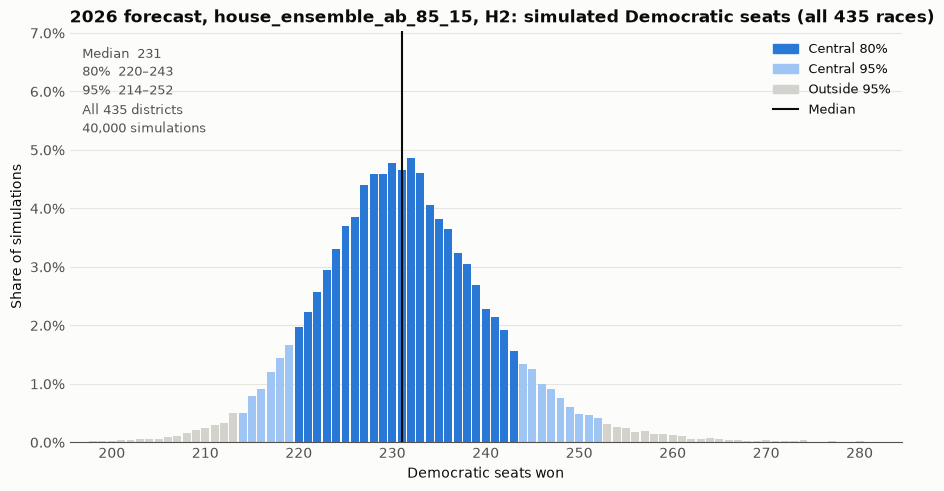

In [18]:
fig, ax = simulation.plot_seat_distribution(
    draws_2026.seats(simulation.DEM),
    year=FORECAST_YEAR,
    actual_seats=None,
    panel_size=HOUSE_SEATS,
    house_size=HOUSE_SEATS,
    title=f"2026 forecast, {CONFIG.name}, H2: simulated Democratic seats (all 435 races)",
)

In [19]:
# The closest races and every race decided by rule
close = forecast_2026[forecast_2026[["p_dem", "p_gop", "p_other"]].max(axis=1) < 0.9]
display(Markdown(f"**{len(close)} races where no party wins 90% of draws**"))
display(simulation.styled(close.sort_values("p_dem")))
display(Markdown("**Races decided by rule** (no Stage 1 margin)"))
simulation.styled(forecast_2026[forecast_2026["treatment"] != "simulated"])

**55 races where no party wins 90% of draws**

,year,state,district,race_type,election_method,treatment,prediction_source,prediction,p_dem,p_gop,p_other,predicted_party,predicted_candidate,candidate_status
88,2026,FL,2,dr,standard,simulated,house_ensemble_ab_85_15,-8.4,10.0%,90.0%,0.0%,R,Austin Rogers,resolved
97,2026,FL,11,dr,standard,simulated,house_ensemble_ab_85_15,-8.1,10.5%,89.5%,0.0%,R,Joe Strada,resolved
90,2026,FL,4,dr,standard,simulated,house_ensemble_ab_85_15,-7.5,12.1%,87.9%,0.0%,R,Aaron Bean,resolved
273,2026,NY,2,dr,standard,simulated,house_ensemble_ab_85_15,-7.4,12.4%,87.6%,0.0%,R,Andrew Garbarino,resolved
113,2026,FL,27,dr,standard,simulated,house_ensemble_ab_85_15,-7.3,12.6%,87.4%,0.0%,R,María Elvira Salazar,resolved
99,2026,FL,13,dr,standard,simulated,house_ensemble_ab_85_15,-7.3,12.9%,87.1%,0.0%,R,Anna Paulina Luna,resolved
254,2026,NJ,2,dr,standard,simulated,house_ensemble_ab_85_15,-6.9,14.0%,86.0%,0.0%,R,Jeff Van Drew,resolved
418,2026,WA,5,dr,top_two,simulated,house_ensemble_ab_85_15,-6.5,15.2%,84.8%,0.0%,R,Michael Baumgartner,resolved
211,2026,MN,1,dr,standard,simulated,house_ensemble_ab_85_15,-6.4,15.4%,84.6%,0.0%,R,Brad Finstad,resolved
172,2026,KY,6,dr,standard,simulated,house_ensemble_ab_85_15,-6.1,16.8%,83.2%,0.0%,R,Ralph Alvarado,resolved


**Races decided by rule** (no Stage 1 margin)

,year,state,district,race_type,election_method,treatment,prediction_source,prediction,p_dem,p_gop,p_other,predicted_party,predicted_candidate,candidate_status
14,2026,AZ,3,dem_vs_3p,standard,third_party,third_party,+nan,99.5%,0.0%,0.5%,D,Yassamin Ansari,resolved
24,2026,CA,4,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,nan,several_D_candidates
27,2026,CA,7,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,nan,several_D_candidates
31,2026,CA,11,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,nan,several_D_candidates
32,2026,CA,12,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,nan,several_D_candidates
34,2026,CA,14,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,nan,several_D_candidates
49,2026,CA,29,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,nan,several_D_candidates
54,2026,CA,34,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,nan,several_D_candidates
57,2026,CA,37,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,nan,several_D_candidates
60,2026,CA,40,gop_vs_gop,top_two,same_party,same_party,+nan,0.0%,100.0%,0.0%,R,nan,several_R_candidates


In [20]:
# Checks: one outcome per race and draw, the overrides, no invented margins, ballot identities, reproducibility
print(simulation.check_forecast(forecast_2026, draws_2026, candidates, house_size=HOUSE_SEATS))
again = simulation.simulate_races(point_2026, ERROR_SCALE_2026, NU, N_SIMS, np.random.default_rng([SEED, FORECAST_YEAR]),
                                  resolvers=RESOLVERS)
print(simulation.check_same_draws(again, draws_2026))

forecast checks passed: 40,000 draws x 435 races


reproducibility check passed: identical draws
